In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("titanic.csv")

In [2]:
known = df.dropna(subset=["Cabin"]).copy()

first_cabin = known["Cabin"].str.split().str[0]        # first cabin if several
known["Deck"] = first_cabin.str[0]
known["cabin_no"] = pd.to_numeric(first_cabin.str.extract(r"(\d+)")[0], errors="coerce")
known["side"] = np.where(known["cabin_no"] % 2 == 1, "Starboard (odd)", "Port (even)")
known.loc[known["cabin_no"].isna(), "side"] = np.nan

known = known[known["Deck"] != "T"]                    # single passenger, drop
print(known["Deck"].value_counts().sort_index())

Deck
A    15
B    47
C    59
D    33
E    32
F    13
G     4
Name: count, dtype: int64


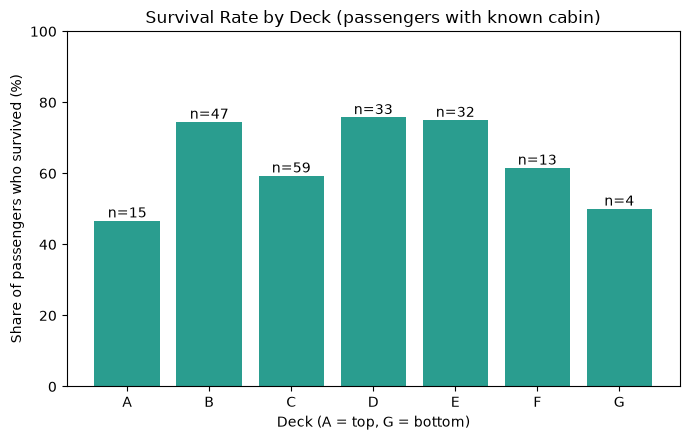

In [3]:
import matplotlib.pyplot as plt

by_deck = known.groupby("Deck")["Survived"].agg(rate="mean", n="size")

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(by_deck.index, by_deck["rate"] * 100, color="#2a9d8f")
ax.bar_label(bars, labels=[f"n={n}" for n in by_deck["n"]])
ax.set_title("Survival Rate by Deck (passengers with known cabin)")
ax.set_xlabel("Deck (A = top, G = bottom)")
ax.set_ylabel("Share of passengers who survived (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [4]:
pos = known.dropna(subset=["cabin_no"]).copy()

def tercile(s):
    return pd.qcut(s.rank(method="first"), 3, labels=["Front", "Middle", "Back"])

pos["section"] = pos.groupby("Deck", group_keys=False)["cabin_no"].apply(tercile)

heat = (pos.pivot_table(index="Deck", columns="section",
                        values="Survived", aggfunc="mean", observed=True) * 100)
counts = pos.pivot_table(index="Deck", columns="section",
                         values="Survived", aggfunc="size", observed=True)

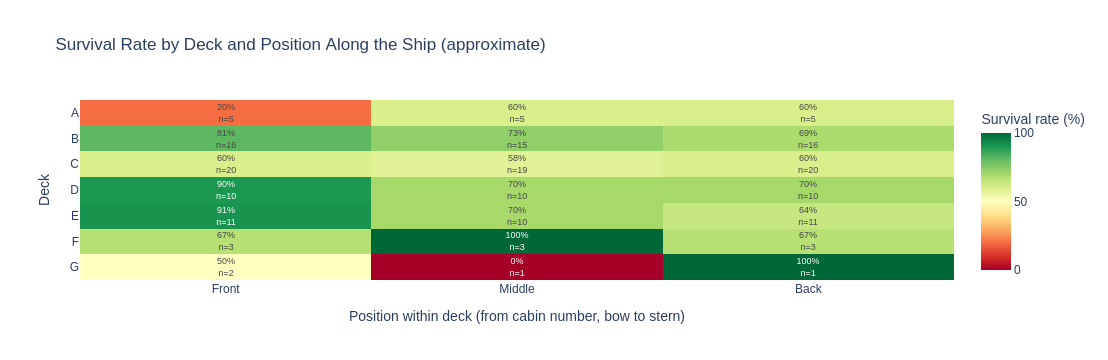

In [5]:
import plotly.graph_objects as go

fig = go.Figure(go.Heatmap(
    z=heat.values, x=heat.columns.astype(str), y=heat.index,
    colorscale="RdYlGn", zmin=0, zmax=100,
    colorbar=dict(title="Survival rate (%)"),
    text=[[f"{v:.0f}%<br>n={int(c)}" if pd.notna(v) else ""
           for v, c in zip(row_v, row_c)]
          for row_v, row_c in zip(heat.values, counts.values)],
    texttemplate="%{text}"))
fig.update_layout(
    title="Survival Rate by Deck and Position Along the Ship (approximate)",
    xaxis_title="Position within deck (from cabin number, bow to stern)",
    yaxis_title="Deck", yaxis_autorange="reversed")   # A at top
fig.show()

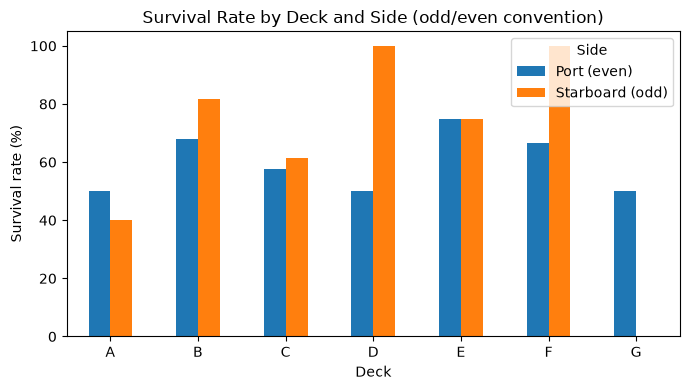

In [6]:
side_rate = pos.groupby(["Deck", "side"])["Survived"].mean().unstack() * 100
side_rate.plot(kind="bar", figsize=(7, 4))
plt.title("Survival Rate by Deck and Side (odd/even convention)")
plt.xlabel("Deck"); plt.ylabel("Survival rate (%)")
plt.legend(title="Side"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()